# TerraSpectra — final review

Think of this as checking a science project before the presentation: make sure every ingredient is present, repeat the important measurement, show what works, and explain the limits. We do not train again or invent a new test set.

## 1. Load the evidence
Open this notebook in VS Code with the project `.venv` kernel. This first part reads committed reports and works without downloading the raw dataset again.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if ROOT.name == "notebooks": ROOT = ROOT.parent
evidence = json.loads((ROOT / "reports/final_review/evidence.json").read_text())
print("Recorded:", evidence["generated_at_utc"])
print(evidence["scope"])

Recorded: 2026-11-11T10:52:46.450753+00:00
Recheck existing development evidence, not an independent test or retraining.


## 2. Did all the ingredients arrive?
A SHA-256 fingerprint helps us recognize the exact file contents. The fresh final-review scan compared every ZIP TIFF with the extracted file and the inventory. Every prepared array was also checked for its shape, datatype and finite values.

In [2]:
data = evidence["dataset"]
print("Files checked:",data["files_checked"])
print("Integrity passed:",data["integrity_passed"])
print("Raw band counts:",data["raw_band_counts"])
print("Splits:",data["split_counts"])
print("Exact duplicate overlap:",data["exact_duplicate_hash_overlap"])

Files checked: 900
Integrity passed: True
Raw band counts: {'125': 741, '126': 159}
Splits: {'train': 480, 'validation': 120, 'unlabelled': 300}
Exact duplicate overlap: {'train / validation': 0, 'train / unlabelled': 0, 'unlabelled / validation': 0}


Zero identical files across splits does not rule out different nearby patches from one source image. That is why independent scene/plant grouping would be needed for a stronger scientific evaluation.

## 3. Can the saved model repeat its answers?
The review reloads both checkpoints, verifies their fingerprints, and recomputes predictions for the same 120 development-validation images. Matching the old confusion matrix demonstrates reproducibility. It does not turn those images into a fresh test set.

In [3]:
for model in evidence["models"]:
    print(model["name"])
    print("Fingerprints:",model["fingerprints"])
    print("Confusion matrix reproduced:",model["saved_confusion_matrix_reproduced"])
    print("Accuracy:",model["recomputed"]["accuracy"],"macro F1:",model["recomputed"]["macro_f1"])

Compact hybrid 3D–2D CNN
Fingerprints: {'manifest_matches': True, 'checkpoint_matches': True, 'preprocessing_matches': True}
Confusion matrix reproduced: True
Accuracy: 0.6583333333333333 macro F1: 0.6346216889588251
Compact CNN + vision transformer
Fingerprints: {'manifest_matches': True, 'checkpoint_matches': True, 'preprocessing_matches': True}
Confusion matrix reproduced: True
Accuracy: 0.7083333333333334 macro F1: 0.7065527065527065


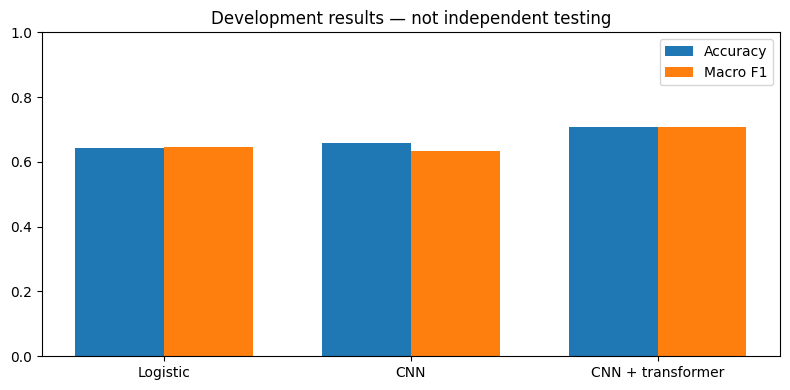

In [4]:
baseline = json.loads((ROOT / "reports/week3/metrics.json").read_text())["baseline"]
metrics = [baseline] + [m["recomputed"] for m in evidence["models"]]
names = ["Logistic", "CNN", "CNN + transformer"]
x = np.arange(3)
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(x-.18,[m["accuracy"] for m in metrics],.36,label="Accuracy")
ax.bar(x+.18,[m["macro_f1"] for m in metrics],.36,label="Macro F1")
ax.set(xticks=x,xticklabels=names,ylim=(0,1),title="Development results — not independent testing")
ax.legend(); fig.tight_layout(); plt.show()

## 4. Better overall does not mean better everywhere
The transformer finds more healthy patches, but its Rust recall is lower than the CNN. Recall means: of the actual examples in a class, how many did we find? A useful final review shows this tradeoff.

In [5]:
for label in ["Health","Other","Rust"]:
    recalls = [m["recomputed"]["per_class"][label]["recall"] for m in evidence["models"]]
    print(label, "CNN recall:",recalls[0], "transformer recall:",recalls[1])

Health CNN recall: 0.3 transformer recall: 0.55
Other CNN recall: 0.85 transformer recall: 0.85
Rust CNN recall: 0.825 transformer recall: 0.725


## 5. Which map claims are proven?
Numerical agreement of the synthetic grid is different from proving actual farm locations. The fresh review checks 80 invented cells. Real-farm registration still needs reliable image coordinates and surveyed references.

In [6]:
print(json.dumps(evidence["synthetic_gis"],indent=2))
print("Earlier API example status:",evidence["previous_api_demonstration"]["patch_status"])
print("Earlier tiled example:",evidence["previous_api_demonstration"]["download_tile_count"],"tiles")

{
  "cells_checked": 80,
  "max_corner_error_degrees": 0.0,
  "tolerance_degrees": 1e-09,
  "boundary_matches": true,
  "center_roundtrips_passed": true,
  "grid_alignment_passed": true,
  "crs": "EPSG:4326",
  "real_farm_alignment": "NOT VALIDATED: synthetic boundary, no surveyed control points",
  "browser_camera_alignment": "NOT VERIFIED: requires live Mapbox pan/zoom/tilt check",
  "row_convention": "Mock rows start south; raster rows start north."
}
Earlier API example status: 200
Earlier tiled example: 6 tiles


The API and memory entries in this evidence file are explicitly historical demonstrations. They are not rerun by the final scientific-check command. The final browser inspection covers separate-page navigation and the no-token diagram controls, not satellite registration.

## 6. Present the project in five steps

1. **Overview:** 900 patches, 125 useful bands, 16 PCA components.
2. **Data quality:** fingerprints, split, memory, synthetic geometry.
3. **Model performance:** real scores and class tradeoffs.
4. **Inference:** saved model, local API, tiled patch-score raster.
5. **Map & analytics:** clearly labelled simulation and timeline.

The five views have their own hash URLs and show only the selected content. Browser navigation works; leaving a page resets its local controls. No week numbers appear in the dashboard navigation.

## 7. Optional: repeat the full evidence review
This requires the local ZIP and prepared data. Leave the switch off to avoid re-reading the dataset unnecessarily. The command checks existing evidence; it does not train a new model.

In [7]:
RUN_REVIEW = False
if RUN_REVIEW:
    import os, subprocess, sys
    archive = Path.home()/"Downloads/beyond-visible-spectrum-ai-for-agriculture-P1.zip"
    subprocess.run([sys.executable,"-m","terraspectra.final_review","--zip",str(archive)],
                   cwd=ROOT,env=dict(os.environ,PYTHONPATH=str(ROOT/"src")),check=True)
else:
    print("Using committed final-review evidence.")

Using committed final-review evidence.


## Final statement

This is a working educational prototype for compatible hyperspectral patch classification, local tiling/API inference and simulated geospatial interaction. It does not establish chemical diagnosis, pixel segmentation, real temporal progression, three-week forecasting, independent farm accuracy or GPU throughput.

Read [the final report](../docs/FINAL_REVIEW.md), [mentor walkthrough](../docs/MENTOR_WALKTHROUGH.md), and [research notes](../docs/FINAL_RESEARCH.md).